# **SUPPLY CHAIN FORECASTING WITH AI**
Today you'll build forecasting models using Gradient Boosting,
a machine learning method that builds hundreds of decision trees
to find patterns in supply chain data.

## **Before You Start: A Note About the Code**

**You do not need to understand the Python code in this notebook.** All the code is pre-written. Your job is to:

1. **Run each cell** (click the play button or press Shift+Enter)
2. **Look at the outputs** — the numbers, charts, and tables that appear
3. **Think critically** about what those outputs mean for the business problem
4. **Discuss** the questions that appear between code sections

The code is here for transparency (so you can see exactly what the AI is doing), not because you need to write or modify it. If a cell produces an error, ask your instructor — it's likely a setup issue, not something you did wrong.

## **Learning Objectives:**

1. Understand how machine learning works on supply chain data
2. Experience AI as "Assistive" - provides predictions, you interpret
3. See limitations: data quality, black box, pattern matching
4. Connect to last week's concepts

## **Business Context**

You manage a global supply chain with shipments across major routes:

* Shanghai → Rotterdam (via Suez)
* Hamburg → New York (Atlantic)
* Singapore → Los Angeles (Pacific)

**Disruptions happen daily:**

*   Geopolitical conflicts (Red Sea crisis, trade wars)
*   Severe weather (typhoons, hurricanes)
*   Port congestion
*   Labor strikes

**Every disruption requires a decision:**

*   Accept the delay? (cheapest, but customer impact)
*   Re-route? (medium cost/time)
*   Expedite via air? (expensive, but fast)
*   Negotiate with carrier? (uncertain)

**Today:** Work with AI to help make these decisions.

# **SETUP: INSTALL & IMPORT PACKAGES**

Run the cell below to install required packages and import libraries.

This will take approximately 30 seconds.

In [ ]:
print("Installing required packages...")
!pip install -q scikit-learn pandas matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    classification_report,
    confusion_matrix,
    accuracy_score
)

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("Setup complete!\n")

# **LOADING THE DATASET**

We'll use an augmented version of the [**Global Supply Chain Disruption & Resilience**](https://www.kaggle.com/datasets/bertnardomariouskono/global-supply-chain-disruption-and-resilience) dataset by Bernardo Mario Uskono on Kaggle.

The original dataset (10,000 rows) provides the business scenario, route structures, and disruption categories. It was augmented to 50,000 rows with designed patterns for this teaching case.

This dataset contains 50,000 shipment records with information about:
- Order details (dates, origins, destinations, products)
- Transportation (modes, routes, lead times)
- Delays and delivery performance
- Disruptions (weather, geopolitical conflicts, port congestion)
- Risk factors (geopolitical risk, weather severity)
- Shipping costs
- Actions taken to handle problems

In [ ]:
# Check if file exists
if not os.path.exists('final_dataset_supply_chain.csv'):
    print(" File not found!")
    print("Please upload the dataset using the file browser on the left.")
    print("Then run this cell again.")
else:
    # Load the dataset
    df = pd.read_csv('final_dataset_supply_chain.csv', parse_dates=['Order_Date'])

    print("Dataset loaded successfully!")
    print(f"  Rows: {df.shape[0]:,}")
    print(f"  Columns: {df.shape[1]}")
    print("\nReady to begin analysis")

Dataset loaded successfully!
  Rows: 50,000
  Columns: 19

Ready to begin analysis


# **INITIAL DATA EXPLORATION**

Let's explore the dataset to understand disruption patterns, delays, and mitigation strategies.

## **Review Data**


In [ ]:
print("Columns in dataset:")
print(df.columns.tolist())
print("\n" + "="*70)

df.head()

Columns in dataset:
['Order_ID', 'Order_Date', 'Origin_City', 'Destination_City', 'Route_Type', 'Transportation_Mode', 'Product_Category', 'Base_Lead_Time_Days', 'Scheduled_Lead_Time_Days', 'Actual_Lead_Time_Days', 'Delay_Days', 'Delivery_Status', 'Disruption_Event', 'Geopolitical_Risk_Index', 'Weather_Severity_Index', 'Inflation_Rate_Pct', 'Shipping_Cost_USD', 'Order_Weight_Kg', 'Mitigation_Action_Taken']



,Order_ID,Order_Date,Origin_City,Destination_City,Route_Type,Transportation_Mode,Product_Category,Base_Lead_Time_Days,Scheduled_Lead_Time_Days,Actual_Lead_Time_Days,Delay_Days,Delivery_Status,Disruption_Event,Geopolitical_Risk_Index,Weather_Severity_Index,Inflation_Rate_Pct,Shipping_Cost_USD,Order_Weight_Kg,Mitigation_Action_Taken
0,ORD-00BCB25B,2024-04-05,"Shanghai, CN","Los Angeles, US",Pacific,Sea,Textiles,18,21,18,0,On Time,No Disruption,0.81,8.9,1.83,1611.81,1781,Standard Shipping
1,ORD-EBDBACB7,2024-09-08,"Tokyo, JP","Singapore, SG",Intra-Asia,Air,Pharmaceuticals,2,5,2,0,On Time,No Disruption,0.70,5.9,2.44,76127.70,8142,Standard Shipping
2,ORD-4052DA06,2025-01-28,"Shenzhen, CN","Rotterdam, NL",Suez,Air,Semiconductors,3,4,4,0,On Time,No Disruption,0.46,8.1,3.86,13699.18,1706,Standard Shipping
3,ORD-03F41ABB,2025-02-04,"Santos, BR","Shanghai, CN",Commodity,Sea,Consumer Electronics,35,36,35,0,On Time,No Disruption,0.88,9.3,1.58,5448.24,5796,Standard Shipping
4,ORD-347A88A6,2025-05-20,"Hamburg, DE","New York, US",Atlantic,Sea,Raw Materials,12,13,12,0,On Time,No Disruption,0.55,2.9,3.12,1215.98,1569,Standard Shipping


## **Data Quality Check**
Before building models, we need to verify data quality.

In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
for i, col in enumerate(df.columns, 1):
    print(f"{i:2d}. {col}")

print("\n" + "="*70)
print("Checking for duplicate rows:")
print("="*70)

print("Duplicate rows:", df.duplicated().sum())

print("\n" + "="*70)
print("Checking for missing values by column:")
print("="*70)
missing = df.isnull().sum()
if missing.sum() == 0:
    print("No missing values found")
else:
    missing_df = pd.DataFrame({
        'Column': missing.index,
        'Missing': missing.values,
        'Percentage': (missing.values / len(df) * 100).round(2)
    })
    print(missing_df[missing_df['Missing'] > 0].to_string(index=False))

    # Fix missing values
    print("\n" + "="*70)
    print("Fixing missing values:")
    print("="*70)

    for col in df.columns:
        if df[col].isnull().any():
            if df[col].dtype in ['float64', 'int64']:
                # Numeric columns: fill with median
                fill_value = df[col].median()
                df[col].fillna(fill_value, inplace=True)
                print(f"✓ {col}: Filled with median ({fill_value:.2f})")
            else:
                # Categorical columns: fill with 'Unknown'
                df[col].fillna('Unknown', inplace=True)
                print(f"✓ {col}: Filled with 'Unknown'")

    # Verify fix
    print(f"\n✓ Missing values after fix: {df.isnull().sum().sum()}")

print("\n" + "="*70)
print("Sample of key columns:")
print("="*70)
print(df[['Disruption_Event', 'Delay_Days', 'Mitigation_Action_Taken']].head())

print("\n" + "="*70)
print("Data types:")
print("="*70)
print(df.dtypes)

Dataset shape: (50000, 19)

Column names:
 1. Order_ID
 2. Order_Date
 3. Origin_City
 4. Destination_City
 5. Route_Type
 6. Transportation_Mode
 7. Product_Category
 8. Base_Lead_Time_Days
 9. Scheduled_Lead_Time_Days
10. Actual_Lead_Time_Days
11. Delay_Days
12. Delivery_Status
13. Disruption_Event
14. Geopolitical_Risk_Index
15. Weather_Severity_Index
16. Inflation_Rate_Pct
17. Shipping_Cost_USD
18. Order_Weight_Kg
19. Mitigation_Action_Taken

Checking for duplicate rows:
Duplicate rows: 0

Checking for missing values by column:
No missing values found

Sample of key columns:
  Disruption_Event  Delay_Days Mitigation_Action_Taken
0    No Disruption           0       Standard Shipping
1    No Disruption           0       Standard Shipping
2    No Disruption           0       Standard Shipping
3    No Disruption           0       Standard Shipping
4    No Disruption           0       Standard Shipping

Data types:
Order_ID                            object
Order_Date                  

## **Basic Statistics**

Now let's look at overall delivery performance.

In [ ]:
# Delivery performance
print("="*70)
print("Delivery Performance:")
print("="*70)
delivery_counts = df['Delivery_Status'].value_counts()
for status, count in delivery_counts.items():
    print(f"{status}: {count:,} ({count/len(df)*100:.1f}%)")

# Delay statistics
print("\n" + "="*70)
print("Delay Statistics:")
print("="*70)
print(df['Delay_Days'].describe())

# Cost statistics
print("\n" + "="*70)
print("Shipping Cost Statistics:")
print("="*70)
print(df['Shipping_Cost_USD'].describe())

## **Disruption Landscape**

What types of disruptions occur most frequently? How severe are the delays?

In [ ]:
print("Disruption Events:")
print(df['Disruption_Event'].value_counts())

print("\nMitigation Actions Taken:")
print(df['Mitigation_Action_Taken'].value_counts())

# Disruption impact
disrupted = df[df['Disruption_Event'] != 'No Disruption']
print(f"\nShipments with disruptions: {len(disrupted):,} ({len(disrupted)/len(df)*100:.1f}%)")
if len(disrupted) > 0:
    print(f"Average delay when disrupted: {disrupted['Delay_Days'].mean():.1f} days")

# No disruption baseline
no_disruption = df[df['Disruption_Event'] == 'No Disruption']
print(f"\nShipments without disruptions: {len(no_disruption):,} ({len(no_disruption)/len(df)*100:.1f}%)")
print(f"Average delay without disruption: {no_disruption['Delay_Days'].mean():.1f} days")

Disruption Events:
Disruption_Event
No Disruption                              44301
Port Congestion                             2441
Geopolitical Conflict (Route Diversion)     1914
Severe Weather (Typhoon/Storm)              1344
Name: count, dtype: int64

Mitigation Actions Taken:
Mitigation_Action_Taken
Standard Shipping        41306
Re-routing                7129
Expedited Air Freight     1565
Name: count, dtype: int64

Shipments with disruptions: 5,699 (11.4%)
Average delay when disrupted: 4.9 days

Shipments without disruptions: 44,301 (88.6%)
Average delay without disruption: 0.7 days


## **Visualizations**

Run the cell below to generate six charts. Here's what to look for:

1. **Delay distribution** (histogram) — How many shipments are on time vs. delayed? Notice the shape of the distribution.
2. **Delays by disruption type** (box plot) — Each box shows the range of delays for a disruption category. The line in the middle is the median. Dots outside the box are outliers.
3. **Risk factors vs. delays** (scatter plot) — Each dot is a disrupted shipment. Color shows delay severity. Look for clusters.
4. **Mitigation actions** (bar chart) — Which actions are most common?
5. **Shipping cost by transport mode** (box plot) — How do costs vary?
6. **Product categories** (bar chart) — What types of goods are being shipped?

**Take your time with these.** The patterns you notice here will help you evaluate the AI models later.

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

# 1. Delay distribution
axes[0,0].hist(df['Delay_Days'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0,0].axvline(df['Delay_Days'].mean(), color='red', linestyle='--',
                  label=f'Mean: {df["Delay_Days"].mean():.1f} days', linewidth=2)
axes[0,0].set_xlabel('Delay (Days)', fontsize=11)
axes[0,0].set_ylabel('Frequency', fontsize=11)
axes[0,0].set_title('Distribution of Shipment Delays', fontsize=13, fontweight='bold')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# 2. Delays by disruption type
disruption_types = df['Disruption_Event'].unique()
bp = axes[0,1].boxplot(
    [df[df['Disruption_Event'] == event]['Delay_Days'].values
     for event in disruption_types],
    labels=disruption_types,
    patch_artist=True,
    boxprops=dict(facecolor='steelblue', color='black', linewidth=1.5),
    whiskerprops=dict(color='black', linewidth=1.5),
    capprops=dict(color='black', linewidth=1.5),
    medianprops=dict(color='red', linewidth=2),
    flierprops=dict(marker='o', markerfacecolor='red', markersize=6, alpha=0.5)
)
axes[0,1].set_title('Delay Days by Disruption Type', fontsize=13, fontweight='bold')
axes[0,1].set_xlabel('Disruption Event', fontsize=11)
axes[0,1].set_ylabel('Delay (Days)', fontsize=11)
axes[0,1].grid(True, alpha=0.3, axis='y')
plt.sca(axes[0,1])
plt.xticks(rotation=0, ha='center', fontsize=9)

# 3. Risk factors colored by delay (disrupted shipments only)
disrupted_only = df[df['Disruption_Event'] != 'No Disruption']
scatter = axes[0,2].scatter(
    disrupted_only['Geopolitical_Risk_Index'],
    disrupted_only['Weather_Severity_Index'],
    c=disrupted_only['Delay_Days'],
    cmap='YlOrRd',
    alpha=0.7,
    s=80,
    edgecolors='black',
    linewidth=0.5
)
axes[0,2].set_xlabel('Geopolitical Risk Index', fontsize=11)
axes[0,2].set_ylabel('Weather Severity Index', fontsize=11)
axes[0,2].set_title('Risk Factors vs Delays\n(Disrupted Shipments Only)',
                    fontsize=13, fontweight='bold')
axes[0,2].grid(True, alpha=0.3)
cbar = plt.colorbar(scatter, ax=axes[0,2])
cbar.set_label('Delay Days', fontsize=10)

# 4. Mitigation actions (horizontal bar for readability)
mitigation_counts = df['Mitigation_Action_Taken'].value_counts()
axes[1,0].barh(range(len(mitigation_counts)), mitigation_counts.values, color='steelblue')
axes[1,0].set_yticks(range(len(mitigation_counts)))
axes[1,0].set_yticklabels(mitigation_counts.index, fontsize=10)
axes[1,0].set_xlabel('Count', fontsize=11)
axes[1,0].set_title('Mitigation Actions Taken', fontsize=13, fontweight='bold')
axes[1,0].grid(True, alpha=0.3, axis='x')
axes[1,0].invert_yaxis()

# 5. Shipping cost by transport mode
transport_modes = df['Transportation_Mode'].unique()
cost_data = [df[df['Transportation_Mode'] == mode]['Shipping_Cost_USD'].values
             for mode in transport_modes]

bp = axes[1,1].boxplot(
    cost_data,
    labels=transport_modes,
    patch_artist=True,
    boxprops=dict(facecolor='lightblue', color='black', linewidth=1.5),
    whiskerprops=dict(color='black', linewidth=1.5),
    capprops=dict(color='black', linewidth=1.5),
    medianprops=dict(color='red', linewidth=2),
    flierprops=dict(marker='o', markerfacecolor='red', markersize=4, alpha=0.3)
)
axes[1,1].set_title('Shipping Cost by Transport Mode', fontsize=13, fontweight='bold')
axes[1,1].set_xlabel('Transportation Mode', fontsize=11)
axes[1,1].set_ylabel('Cost (USD)', fontsize=11)
axes[1,1].grid(True, alpha=0.3, axis='y')
axes[1,1].set_ylim(bottom=0)

# 6. Product categories
product_counts = df['Product_Category'].value_counts()
axes[1,2].barh(range(len(product_counts)), product_counts.values, color='mediumseagreen')
axes[1,2].set_yticks(range(len(product_counts)))
axes[1,2].set_yticklabels(product_counts.index, fontsize=10)
axes[1,2].set_xlabel('Count', fontsize=11)
axes[1,2].set_title('Product Categories', fontsize=13, fontweight='bold')
axes[1,2].grid(True, alpha=0.3, axis='x')
axes[1,2].invert_yaxis()

plt.tight_layout()
plt.show()

## **Discussion Questions**

Take 10 minutes to discuss these questions with your group. We'll share insights afterward.



### **1. The On-Time Reality**

Look at the first chart showing the distribution of delays.

**Discuss:**
- What percentage of shipments arrive on time? Is this good or bad for supply chain operations?
- Here's the challenge: Should we build AI to predict all shipments, or focus on the minority that might be delayed?
- If you were managing this supply chain, where would you invest your resources - monitoring everything or focusing on high-risk shipments?

### **2. The Disruptions**

The second chart shows different disruption types cause very different delays.

**Discuss:**
- Which disruption type causes the longest delays? Which causes the shortest? Why might that be?
- Notice the "No Disruption" category - does it have any outliers with significant delays? What could cause delays when there's no official disruption event?
- If we only look at disruption labels, we miss those unlabeled delays. What other signals might predict them?

### **3. The Risk Index Pattern**

The bubble chart shows the relationship between risk indices and delays.

**Discuss:**
- Do you see a pattern? What happens when both geopolitical risk and weather severity are high?
- Are there any high-risk shipments that still arrived on time? What might explain that?
- Do you think the AI can learn this pattern?

### **4. Mitigation Decisions**

Look at the chart showing mitigation actions taken.

**Discuss:**
- Which mitigation action is most common? Why?
- Air freight costs significantly more than sea freight. When is that cost justified?
- If you're choosing between "absorb a delay" vs. "pay premium to expedite," what factors matter?
- Can AI learn to make these cost-benefit decisions? Should it?

### **5. The Class Imbalance Problem**

Look back at the delay distribution chart.

**Discuss:**
- Most shipments are in one category (on-time), fewer in another (delayed). What percentage split do you see?
- If you train an AI on this data, what will it probably learn?
  *(Hint: "Just predict everything is on-time" gives you the majority percentage as accuracy!)*
- This is called **class imbalance** - it's a major challenge in real-world AI
- What if our historical data only logged some disruptions? How would missing data affect what the AI learns?

### **6. Looking Ahead to Tasks 1 & 2**

Based on what you've seen in these charts:

**Make predictions:**
1. Which features will matter most for predicting delays? (Task 1)
2. Will the AI rely too heavily on disruption labels, or will it learn from risk indices and routes too?
3. For recommending mitigation actions (Task 2), what should the AI optimize for - speed? cost? customer satisfaction?

**Write down your predictions.** We'll test them when we build the models.

# **Task 1: Predictive AI - Delay Forecasting**

### **Business Question**
**"How many days will this shipment be delayed?"**

### **Why we need this**

Supply chain managers need to anticipate problems, not just react to them:
- **Plan ahead:** Notify customers before delays happen
- **Resource allocation:** Prioritize high-risk shipments for intervention
- **Cost management:** Decide whether to expedite or accept delays
- **Performance tracking:** Identify systemic bottlenecks in routes or carriers

**The challenge:** We need predictions EARLY - ideally before disruptions are confirmed - so we can take action.

### **Use Cases**
- Alert customers proactively: "Your shipment may be 3-5 days late"
- Prioritize warehouse staff: "These 20 orders need attention today"
- Trigger automatic workflows: "If predicted delay > 7 days, escalate to manager"
- Optimize inventory: "Delay expected, order backup stock from alternative supplier"

### **AI Type**
**Assistive AI (Predictive)** - The model forecasts delays, humans decide what to do:
- Manager reviews predictions and decides which to act on
- AI doesn't know customer priority or contractual obligations
- Predictions guide attention, not replace judgment

### **Approach**
- **Input:** Risk indices (geopolitical risk, weather severity), route characteristics, order details, disruption events
- **Output:** Predicted delay in days (regression)
- **Model:** Gradient Boosting Regressor

### **The Production Reality Test**

Here's the critical question we'll explore:
- **In the lab:** We have complete information (including disruption labels)
- **In production:** Disruptions aren't always known when we need predictions

**We'll test both scenarios:**
1. **With all features (including disruptions)** - How accurate can we be with complete data?
2. **Without disruption labels** - Can we predict delays using only risk signals and route data available BEFORE problems occur?

This gap between lab performance and production reality is a key lesson in AI deployment. The best model uses data you'll actually have when you need the prediction.

## **Step 1: Feature Engineering**

Machine learning models require numeric inputs. We'll transform dates and text categories into features the AI can learn from.

**Features we'll create:**

**Temporal patterns** (from Order_Date):
- `month`, `quarter`, `day_of_week` - Captures seasonality (Q3 = typhoon season, winter = storm season)

**Risk severity flags** (binary thresholds):
- `high_geopolitical_risk` - Flag when Geopolitical_Risk_Index > 0.7
- `severe_weather` - Flag when Weather_Severity_Index > 7

**Categorical encoding** (text → numbers):
- `Route_Type_encoded` - Pacific, Suez, Atlantic, etc. → 0, 1, 2, 3...
- `Transportation_Mode_encoded` - Sea, Air, Rail, Road → numbers
- `Product_Category_encoded` - Semiconductors, Textiles, etc. → numbers
- `Disruption_Event_encoded` - Port Congestion, Weather, Conflict → numbers

**Note:** The dataset already includes continuous risk indices (`Geopolitical_Risk_Index`, `Weather_Severity_Index`) that the model will use alongside these engineered features. The AI learns patterns like "high geopolitical risk (0.85) + severe weather (8.5) + Pacific route + Q3 → delays likely"

---

In [ ]:
df_task1 = df.copy()

# Temporal features
df_task1['Order_Date'] = pd.to_datetime(df_task1['Order_Date'])
df_task1['month'] = df_task1['Order_Date'].dt.month
df_task1['quarter'] = df_task1['Order_Date'].dt.quarter
df_task1['day_of_week'] = df_task1['Order_Date'].dt.dayofweek

# Risk flags
df_task1['high_geopolitical_risk'] = (df_task1['Geopolitical_Risk_Index'] > 0.7).astype(int)
df_task1['severe_weather'] = (df_task1['Weather_Severity_Index'] > 7).astype(int)

# Encode categorical variables
categorical_cols = ['Origin_City', 'Destination_City', 'Route_Type',
                   'Transportation_Mode', 'Product_Category', 'Disruption_Event']

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_task1[f'{col}_encoded'] = le.fit_transform(df_task1[col].fillna('Unknown'))
    label_encoders[col] = le

print("Features prepared")

Features prepared


## **Step 2: Select Features & Split Data**

We selected 13 features based on what would realistically be available for prediction:

**Risk indicators:** Geopolitical risk index, weather severity index, inflation rate (these capture underlying conditions that cause delays)  
**Route & logistics:** Route type, transport mode, product category  
**Temporal patterns:** Month, quarter (seasonality matters - typhoons in Q3, winter storms in Q1/Q4)  
**Physical characteristics:** Base lead time, weight  
**Disruption events:** Disruption type (when available - more on this in the production reality test)  
**Engineered flags:** High geopolitical risk, severe weather thresholds

**What we excluded:**
- IDs and dates (not predictive)
- Origin/destination cities (captured by Route_Type)
- Scheduled/Actual lead time (redundant or target leakage)
- Shipping cost (calculated after delays, could leak future information)
- Delivery status (derived from delays)
- Mitigation actions (these are responses to delays, not predictors)

Then we split the data into training (80%) and test (20%) sets.

In [ ]:
feature_cols = [
    'Base_Lead_Time_Days', 'Order_Weight_Kg',
    'Geopolitical_Risk_Index', 'Weather_Severity_Index', 'Inflation_Rate_Pct',
    'Route_Type_encoded', 'Transportation_Mode_encoded',
    'Product_Category_encoded', 'Disruption_Event_encoded',
    'month', 'quarter', 'high_geopolitical_risk', 'severe_weather'
]

X = df_task1[feature_cols]
y = df_task1['Delay_Days']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set: {len(X_train):,} shipments ({len(X_train)/len(df)*100:.1f}%)")
print(f"Test set: {len(X_test):,} shipments ({len(X_test)/len(df)*100:.1f}%)")
print(f"\nFeatures: {len(feature_cols)}")

Training set: 40,000 shipments (80.0%)
Test set: 10,000 shipments (20.0%)

Features: 13


## **Step 3: Train the Gradient Boosting Model**

**What is Gradient Boosting?**

Gradient Boosting builds hundreds of simple decision trees sequentially, where each new tree learns from the mistakes of previous trees. Think of it like iterative learning:
- Tree 1: "High geo risk → predict 5-day delay"
- Tree 2: "Actually, if it's also Pacific route in Q3, add 2 more days"
- Tree 3: "And if weather severity > 8, add another day"
- ...continues for hundreds of trees

This makes it excellent for:
- **Capturing complex interactions** (geo risk + weather + route + season)
- **Handling mixed data types** (numbers, categories, flags)
- **Feature importance** (tells us which features matter most)

**Why use it for supply chain delays?**
- Delays result from COMBINATIONS of factors (not just one thing)
- We have both continuous (risk indices) and categorical (routes) features
- We want to understand WHICH factors drive predictions

Training will take approximately 30-60 seconds as the model builds ~100 decision trees.

In [ ]:
model_delay = GradientBoostingRegressor(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

print("Training model...")
model_delay.fit(X_train, y_train)
print("Training complete")

Training model...
Training complete


## **Step 4: Evaluate Model Performance**

How accurate are our delay predictions? We use three metrics to evaluate how well the model predicts delays:

#### **Mean Absolute Error (MAE)**
**What it is:** Average difference between predicted and actual delays  
**Units:** Days  
**Interpretation:** "On average, predictions are off by X days"  
**Example:** MAE = 0.8 means predictions are typically within ±1 day  
**Lower is better:** MAE = 0 would be perfect predictions

#### **Root Mean Squared Error (RMSE)**
**What it is:** Like MAE, but penalizes large errors more heavily  
**Units:** Days  
**Why it's useful:** A prediction that's off by 10 days is worse than 10 predictions each off by 1 day. RMSE captures this.  
**Lower is better:** RMSE ≥ MAE always (equal only if all errors are identical)

#### **R² Score (Coefficient of Determination)**
**What it is:** How much of the variance in delays the model explains  
**Range:** -∞ to 1.0  
**Interpretation:**  
- **R² = 1.0** → Perfect predictions  
- **R² = 0.75** → Model explains 75% of variance (good - this is realistic for complex systems)  
- **R² = 0.5** → Model explains half the variance (moderate)  
- **R² = 0.0** → Model no better than predicting the average delay every time  
- **R² < 0** → Model worse than just predicting the average (bad!)

**For supply chain predictions:**
- R² > 0.75 → Good model (captures most patterns despite inherent randomness)
- R² = 0.5-0.75 → Moderate (useful but missing some signals)
- R² < 0.5 → Weak (too much unexplained variance)

**Remember:** Even good models can't predict everything - weather changes, human factors, and unexpected events create inherent uncertainty in supply chains.

In [ ]:
y_pred = model_delay.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("="*70)
print(f"Mean Absolute Error (MAE):      {mae:.2f} days")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} days")
print(f"R² Score:                       {r2:.3f}")
print()
print("INTERPRETATION:")
print(f"├─ On average, predictions are off by {mae:.2f} days")
print(f"├─ The model explains {r2*100:.1f}% of delay variance")
print(f"└─ For a 2-day predicted delay, actual is likely {2-mae:.1f} to {2+mae:.1f} days")

MODEL PERFORMANCE
Mean Absolute Error (MAE):      0.77 days
Root Mean Squared Error (RMSE): 1.30 days
R² Score:                       0.755

INTERPRETATION:
├─ On average, predictions are off by 0.77 days
├─ The model explains 75.5% of delay variance
└─ For a 2-day predicted delay, actual is likely 1.2 to 2.8 days


## **Step 5: Visualize Predictions & Feature Importance**

Visualizations help us understand two critical questions:

**1. How accurate are the predictions?**
We'll plot predicted delays vs. actual delays. If the model is good, points should cluster along a diagonal line (predicted = actual). Scatter away from the line shows where the model struggles.

**2. Which features drive the predictions?**
Feature importance tells us which variables the model relies on most. This reveals:
- What really causes delays (geopolitical risk? weather? routes?)
- Which data we should prioritize collecting
- What features we could remove without hurting performance

**Important for deployment:**
If the model heavily relies on features we won't have in production (like disruption labels that come after delays), we need to know that now.

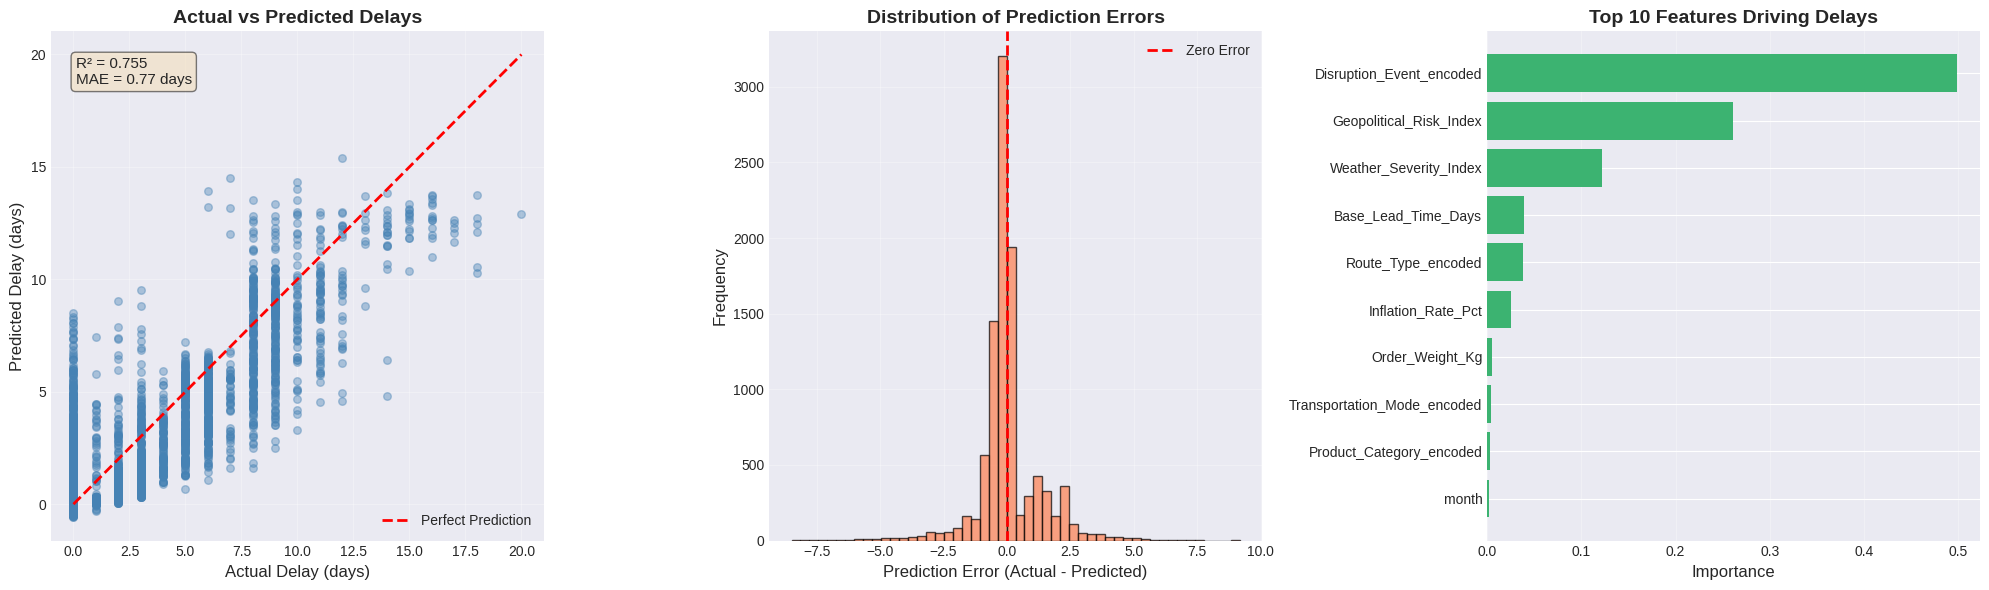


Top 5 Most Important Features:
  Disruption_Event_encoded       0.4985
  Geopolitical_Risk_Index        0.2612
  Weather_Severity_Index         0.1223
  Base_Lead_Time_Days            0.0387
  Route_Type_encoded             0.0379


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.4, s=30, color='steelblue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
             'r--', lw=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual Delay (days)', fontsize=12)
axes[0].set_ylabel('Predicted Delay (days)', fontsize=12)
axes[0].set_title('Actual vs Predicted Delays', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].text(0.05, 0.95, f'R² = {r2:.3f}\nMAE = {mae:.2f} days',
             transform=axes[0].transAxes, verticalalignment='top', fontsize=11,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# 2. Prediction errors
errors = y_test - y_pred
axes[1].hist(errors, bins=50, edgecolor='black', alpha=0.7, color='coral')
axes[1].axvline(0, color='red', linestyle='--', lw=2, label='Zero Error')
axes[1].set_xlabel('Prediction Error (Actual - Predicted)', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)
axes[1].set_title('Distribution of Prediction Errors', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# 3. Feature importance
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': model_delay.feature_importances_
}).sort_values('Importance', ascending=False).head(10)

axes[2].barh(range(len(importance_df)), importance_df['Importance'], color='mediumseagreen')
axes[2].set_yticks(range(len(importance_df)))
axes[2].set_yticklabels(importance_df['Feature'], fontsize=10)
axes[2].set_xlabel('Importance', fontsize=12)
axes[2].set_title('Top 10 Features Driving Delays', fontsize=14, fontweight='bold')
axes[2].invert_yaxis()
axes[2].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

print("\nTop 5 Most Important Features:")
for idx, row in importance_df.head().iterrows():
    print(f"  {row['Feature']:30s} {row['Importance']:.4f}")

In [ ]:
# Try me: Forecast delays without the disruption label
# Set this to True to include the label. Rerun this cell to compare.
include_disruption_label = False

# Keep the same shipments and model settings. Change only the inputs.
trial_features = [
    feature for feature in X_train.columns
    if include_disruption_label or feature != 'Disruption_Event_encoded'
]
trial_delay_model = GradientBoostingRegressor(**model_delay.get_params())
trial_delay_model.fit(X_train[trial_features], y_train)
trial_delays = trial_delay_model.predict(X_test[trial_features])

def delay_comparison_scores(predictions):
    return {
        'MAE (days)': mean_absolute_error(y_test, predictions),
        'RMSE (days)': np.sqrt(mean_squared_error(y_test, predictions)),
        'R²': r2_score(y_test, predictions),
    }

trial_label = 'Try me: label included' if include_disruption_label else 'Try me: label excluded'
delay_comparison = pd.DataFrame({
    'Original model': delay_comparison_scores(y_pred),
    trial_label: delay_comparison_scores(trial_delays),
})
from IPython.display import display
display(delay_comparison.round(3))

### **Discussion Questions - Task 1**

**Spend 15 minutes discussing with your group:**



### **1. Model Performance**

Look at your R² score and MAE.

**Discuss:**
- Is this performance good enough to deploy? What's your threshold?
- Most shipments arrive on time - could the model just be learning "predict near zero most of the time"?
- What would convince you this model is actually useful versus just fitting noise?

### **2. Feature Importance**

Look at which features drive predictions.

**Discuss:**
- Which feature dominates? Is this what you expected?
- What's the split between "what actually happened" (disruption labels) versus "what we could predict beforehand" (risk signals)?
- If one feature accounts for most predictions, is this a robust model or a fragile one?


### **3. Production Reality**

Think about when you'd actually use this model.

**Discuss:**
- When do you need delay predictions? Before shipments leave, or after problems occur?
- When do you get disruption labels? Before delays or after?
- What happens to your model's accuracy if you remove features that aren't available when you need predictions?


### **4. Causation vs. Correlation**

The model learned statistical patterns in historical data.

**Discuss:**
- Does the model understand WHY disruptions cause delays? Or just THAT they correlate?
- What happens when a new type of disruption emerges that wasn't in the training data?
- Can pattern-matching replace domain expertise about supply chain dynamics?


### **5. Deployment Decision**

You have accuracy metrics and feature importance. Now what?

**Discuss:**
- Would you deploy this model in production? Why or why not?
- What questions would you ask before putting this in front of real customers?
- What could go wrong if this model makes bad predictions? Who bears the cost?


# **Task 2: Mitigation Recommendation with Prescriptive AI**

## **Business Question**
**"Given a delayed shipment, what action should we take?"**

## **Prediction → Prescription**

**Task 1 taught us:**
- We can predict delays reasonably well using risk signals and route data
- Risk indices (geopolitical, weather) and disruption labels both contribute to predictions
- Disruption labels are the strongest signal when available, but risk indices provide early warning
- But knowing "it will be late" isn't enough

**Task 2 asks:**
- What should we do about the delay?
- Accept it? Re-route? Expedite via air freight?
- How do we balance cost vs speed vs customer satisfaction?

## **Use Cases**
- Recommend mitigation actions when delays are predicted
- Balance trade-offs (cost vs time vs risk)
- Provide decision support for supply chain managers
- Ensure consistent decision-making across teams

## **AI Type**
**Assistive AI** - The model recommends actions, but humans make final decisions based on:
- Customer relationship value
- Strategic priorities
- Budget constraints
- Situational context the AI doesn't know

## **Approach**
- **Input:** Disruption type, route, product, risk factors, predicted delay
- **Output:** Recommended mitigation action (classification)
- **Model:** Gradient Boosting Classifier
- **Three possible actions:** Standard Shipping, Re-routing, Expedited Air Freight

`Mitigation_Action_Taken` is the outcome the classifier learns to predict. It tells us which action was recorded for shipments like these. To judge whether those actions helped, we would need evidence about delivery outcomes or costs.

Look for `Predicted_Delay` in the feature list. The first model produces this delay forecast, and the second model uses it as an input.

## **Step 1: Understanding the Target Variable**

**What are we predicting?**

In Task 1, we predicted "how many days" (a number). In Task 2, we're predicting "which action to take" (a category).

**The three mitigation actions:**

When supply chain managers face delays, they typically choose between:
- **Standard Shipping** - Accept the delay, no intervention
- **Re-routing** - Change the route to avoid congestion or risks
- **Expedited Air Freight** - Pay premium for faster delivery

Let's see what patterns exist in the historical data:

In [ ]:
print("Mitigation Actions in the Dataset:")
print("="*70)
print(df['Mitigation_Action_Taken'].value_counts())

print("\nMitigation Actions by Disruption Type:")
print("="*70)
mitigation_by_disruption = pd.crosstab(
    df['Disruption_Event'].fillna('No Disruption'),
    df['Mitigation_Action_Taken'],
    normalize='index'
) * 100

print(mitigation_by_disruption.round(1))

Mitigation Actions in the Dataset:
Mitigation_Action_Taken
Standard Shipping        41306
Re-routing                7129
Expedited Air Freight     1565
Name: count, dtype: int64

Mitigation Actions by Disruption Type:
Mitigation_Action_Taken                  Expedited Air Freight  Re-routing  \
Disruption_Event                                                             
Geopolitical Conflict (Route Diversion)                   24.0        65.3   
No Disruption                                              1.5        10.4   
Port Congestion                                           11.6        29.2   
Severe Weather (Typhoon/Storm)                            10.1        40.3   

Mitigation_Action_Taken                  Standard Shipping  
Disruption_Event                                            
Geopolitical Conflict (Route Diversion)               10.7  
No Disruption                                         88.0  
Port Congestion                                       59.2  
Severe W

## **Step 2: Feature Engineering for Task 2**

**Building decision-relevant features:**

We'll create a feature set focused on what managers need to decide on mitigation actions:

- **Delay severity:** Predicted delay from Task 1 (binned into categories: minor, moderate, severe)
- **Disruption context:** Type of disruption, risk indices
- **Product/route characteristics:** Product category, route type, transportation mode
- **Temporal factors:** Month, quarter (seasonal patterns)

**Key addition:** We include the predicted delay from Task 1 as a feature, connecting the two tasks into a pipeline.

In [ ]:
df_task2 = df.copy()

# Add predicted delays from Task 1 as a feature
df_task2_features = df_task2.copy()
for col in categorical_cols:
    df_task2_features[f'{col}_encoded'] = label_encoders[col].transform(
        df_task2_features[col].fillna('Unknown')
    )

# Add temporal and risk features
df_task2_features['month'] = pd.to_datetime(df_task2_features['Order_Date']).dt.month
df_task2_features['quarter'] = pd.to_datetime(df_task2_features['Order_Date']).dt.quarter
df_task2_features['high_geopolitical_risk'] = (df_task2_features['Geopolitical_Risk_Index'] > 0.7).astype(int)
df_task2_features['severe_weather'] = (df_task2_features['Weather_Severity_Index'] > 7).astype(int)

# Get predicted delays from Task 1 model
X_task2_for_prediction = df_task2_features[feature_cols]
df_task2['Predicted_Delay'] = model_delay.predict(X_task2_for_prediction)

# Create strategic features
high_value_products = ['Semiconductors', 'Pharmaceuticals', 'Aerospace_Parts']
df_task2['is_high_value'] = df_task2['Product_Category'].isin(high_value_products).astype(int)

df_task2['delay_severity'] = pd.cut(
    df_task2['Delay_Days'],
    bins=[-1, 0, 3, 7, 100],
    labels=['None', 'Minor', 'Moderate', 'Severe']
)

print("Features prepared for Task 2")
print(f"\nNew features created:")
print(f"  • Predicted_Delay (from Task 1 model)")
print(f"  • is_high_value (product prioritization)")
print(f"  • delay_severity (categorized impact)")

Features prepared for Task 2

New features created:
  • Predicted_Delay (from Task 1 model)
  • is_high_value (product prioritization)
  • delay_severity (categorized impact)


## **Step 3: Select Features & Split Data**

We select features relevant to mitigation decisions:
- Disruption type, risk indices (geopolitical, weather)
- Route type, transportation mode, product category
- Predicted delay from Task 1
- Engineered flags (high geopolitical risk, severe weather, high-value products)

Then split into training (80%) and test (20%) sets.

In [ ]:
# Features for mitigation recommendation
feature_cols_task2 = [
    'Base_Lead_Time_Days', 'Order_Weight_Kg',
    'Geopolitical_Risk_Index', 'Weather_Severity_Index', 'Inflation_Rate_Pct',
    'Route_Type_encoded', 'Transportation_Mode_encoded',
    'Product_Category_encoded', 'Disruption_Event_encoded',
    'Predicted_Delay', 'is_high_value',
    'Shipping_Cost_USD'
]

# Encode features
for col in categorical_cols:
    if f'{col}_encoded' not in df_task2.columns:
        df_task2[f'{col}_encoded'] = label_encoders[col].transform(
            df_task2[col].fillna('Unknown')
        )

X_task2 = df_task2[feature_cols_task2]
y_task2 = df_task2['Mitigation_Action_Taken']

# Encode target variable
le_mitigation = LabelEncoder()
y_task2_encoded = le_mitigation.fit_transform(y_task2)

# Split data
X_train_t2, X_test_t2, y_train_t2, y_test_t2 = train_test_split(
    X_task2, y_task2_encoded, test_size=0.2, random_state=42
)

print(f"Training set: {len(X_train_t2):,} shipments")
print(f"Test set: {len(X_test_t2):,} shipments")
print(f"Features: {len(feature_cols_task2)}")

print(f"\nMitigation actions (target classes):")
for i, action in enumerate(le_mitigation.classes_):
    count = (y_task2 == action).sum()
    print(f"  {i}: {action:30s} ({count:,})")

Training set: 40,000 shipments
Test set: 10,000 shipments
Features: 12

Mitigation actions (target classes):
  0: Expedited Air Freight          (1,565)
  1: Re-routing                     (7,129)
  2: Standard Shipping              (41,306)


## **Step 4: Train the Classification Model**

**What is Multi-class Classification?**

Unlike Task 1 (predicting a number), we're now predicting which category an observation belongs to.

**How it works:**
- The model learns patterns: "High-value products + severe delays → Expedited Air Freight"
- "Minor delays + low-value products → Standard Shipping"
- "Moderate delays + flexible routes → Re-routing"

Each training example shows: "Given this situation, managers chose this action"

The model builds decision rules based on historical patterns.

**Why use Gradient Boosting for classification?**
- Handles the same complex interactions (delay + product + route → action)
- Works with our mix of numeric and categorical features
- Provides feature importance (which factors drive recommendations?)

Training will take a few minutes as the model learns from historical mitigation decisions.

In [ ]:
model_mitigation = GradientBoostingClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42
)

print("Training mitigation recommendation model...")
model_mitigation.fit(X_train_t2, y_train_t2)
print("Training complete")

Training mitigation recommendation model...
Training complete


## **Step 5: Evaluate Model Performance**

**How well does the model recommend the right mitigation actions?**

In Task 1, we measured how close predictions were to actual delay days (MAE, RMSE, R²).

In Task 2, we measure how often the model recommends the correct action.

**Classification Accuracy:**
- **What it is:** Percentage of correct recommendations
- **Interpretation:** "The model recommends the right action X% of the time"
- **Higher is better:** 100% = perfect, 33% = random guessing (three options)

**Confusion Matrix:**
Shows where the model gets it right and where it makes mistakes:
- **Diagonal:** Correct recommendations
- **Off-diagonal:** Mistakes (what it predicted vs. what managers actually chose)

**What's "good" accuracy?**
- **>85%** - Excellent, ready to deploy
- **70-85%** - Good, useful with human oversight
- **<70%** - Weak, needs improvement or more features

**Remember:** This model learns from historical decisions. If managers made inconsistent choices, the model will struggle. High accuracy means managers followed consistent patterns that the AI could learn.

In [ ]:
y_pred_t2 = model_mitigation.predict(X_test_t2)

accuracy = accuracy_score(y_test_t2, y_pred_t2)

print("MODEL PERFORMANCE - MITIGATION RECOMMENDATION")
print("="*70)
print(f"Overall Accuracy: {accuracy*100:.1f}%")
print(f"\nThis means: The model correctly recommends the right action")
print(f"{accuracy*100:.1f}% of the time based on historical patterns.")

print("\n" + "="*70)
print("DETAILED PERFORMANCE BY ACTION:")
print("="*70)
print(classification_report(
    y_test_t2,
    y_pred_t2,
    target_names=le_mitigation.classes_,
    digits=3
))

MODEL PERFORMANCE - MITIGATION RECOMMENDATION
Overall Accuracy: 89.7%

This means: The model correctly recommends the right action
89.7% of the time based on historical patterns.

DETAILED PERFORMANCE BY ACTION:
                       precision    recall  f1-score   support

Expedited Air Freight      0.821     0.554     0.661       307
           Re-routing      0.757     0.500     0.602      1463
    Standard Shipping      0.914     0.980     0.946      8230

             accuracy                          0.897     10000
            macro avg      0.831     0.678     0.737     10000
         weighted avg      0.888     0.897     0.887     10000



## **Step 6: Visualize Model Performance**

Let's examine how well the model performs across different mitigation actions.

**What we'll see:**

**1. Confusion Matrix:**
Shows actual vs. predicted recommendations. Perfect predictions would show up only on the diagonal (top-left to bottom-right). Off-diagonal cells show mistakes.

**2. Feature Importance:**
Which factors most influence mitigation recommendations? Delay severity? Product type? Risk levels?

**3. Performance by Action:**
Does the model perform equally well for all three actions, or better for some than others?

In [ ]:
# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (16, 5)

# Create figure with 2 subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ═══════════════════════════════════════════════════════════════
# 1. CONFUSION MATRIX
# ═══════════════════════════════════════════════════════════════

cm = confusion_matrix(y_test_t2, y_pred_t2)
action_labels = ['Expedited Air\nFreight', 'Re-routing', 'Standard\nShipping']

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=action_labels,
            yticklabels=action_labels,
            cbar_kws={'label': 'Number of Predictions'},
            ax=axes[0])
axes[0].set_title('Confusion Matrix - Actual vs. Predicted Actions', fontsize=14, fontweight='bold', pad=15)
axes[0].set_ylabel('Actual Action Taken', fontsize=12)
axes[0].set_xlabel('Predicted Action', fontsize=12)

# ═══════════════════════════════════════════════════════════════
# 2. FEATURE IMPORTANCE
# ═══════════════════════════════════════════════════════════════

importance_df = pd.DataFrame({
    'Feature': feature_cols_task2,
    'Importance': model_mitigation.feature_importances_
}).sort_values('Importance', ascending=True).tail(10)

axes[1].barh(importance_df['Feature'], importance_df['Importance'], color='steelblue')
axes[1].set_title('Top 10 Feature Importance - Mitigation Recommendations', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Importance', fontsize=12)
axes[1].set_ylabel('Feature', fontsize=12)

# Add value labels on bars
for i, v in enumerate(importance_df['Importance']):
    axes[1].text(v + 0.01, i, f'{v:.4f}', va='center', fontsize=10)

plt.tight_layout()
plt.show()

# ═══════════════════════════════════════════════════════════════
# 3. PERFORMANCE BY ACTION (separate figure)
# ═══════════════════════════════════════════════════════════════

# Get classification report as dict
report = classification_report(y_test_t2, y_pred_t2,
                               target_names=le_mitigation.classes_,
                               output_dict=True)

actions = list(le_mitigation.classes_)

metrics_data = {
    'Action': actions,
    'Precision': [report[action]['precision'] for action in actions],
    'Recall': [report[action]['recall'] for action in actions],
    'F1-Score': [report[action]['f1-score'] for action in actions],
    'Support': [report[action]['support'] for action in actions]
}

metrics_df = pd.DataFrame(metrics_data)

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(actions))
width = 0.25

bars1 = ax.bar(x - width, metrics_df['Precision'], width, label='Precision', color='steelblue')
bars2 = ax.bar(x, metrics_df['Recall'], width, label='Recall', color='darkorange')
bars3 = ax.bar(x + width, metrics_df['F1-Score'], width, label='F1-Score', color='forestgreen')

ax.set_ylabel('Score', fontsize=12)
ax.set_title('Model Performance by Mitigation Action', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(actions, fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim(0, 1.1)

# Add value labels on bars
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.2f}',
                ha='center', va='bottom', fontsize=9)

# Add support counts
support_text = '\n'.join([f"{action}: {int(support):,} samples"
                          for action, support in zip(actions, metrics_df['Support'])])
ax.text(0.98, 0.02, f'Sample Sizes:\n{support_text}',
        transform=ax.transAxes,
        fontsize=10,
        verticalalignment='bottom',
        horizontalalignment='right',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("Top 5 Most Important Features:")
print("="*70)
top_features = importance_df.tail(5).sort_values('Importance', ascending=False)
for idx, row in top_features.iterrows():
    print(f"  {row['Feature']:30s} {row['Importance']:.4f}")

In [ ]:
# Try me: Compare a shipping rule with the mitigation model
# Change either threshold (in days) and rerun this cell.
reroute_after_days = 3
expedite_after_days = 7

if not 0 <= reroute_after_days < expedite_after_days < np.inf:
    raise ValueError('Use nonnegative thresholds and set the expedite threshold higher than the reroute threshold.')

# Use the same delay forecast and test shipments as the mitigation model.
# For this example rule, delays at or below the reroute threshold stay on standard shipping.
rule_delays = X_test_t2['Predicted_Delay']
rule_actions = np.select(
    [rule_delays > expedite_after_days, rule_delays > reroute_after_days],
    ['Expedited Air Freight', 'Re-routing'],
    default='Standard Shipping',
)
recorded_actions = le_mitigation.inverse_transform(y_test_t2)
model_actions = le_mitigation.inverse_transform(y_pred_t2)

def action_comparison_scores(predicted_actions):
    scores = {'Overall agreement (%)': 100 * np.mean(predicted_actions == recorded_actions)}
    for action in le_mitigation.classes_:
        recorded_as_action = recorded_actions == action
        scores[f'Recall: {action} (%)'] = (
            100 * np.mean(predicted_actions[recorded_as_action] == action)
            if recorded_as_action.any() else np.nan
        )
    return scores

action_comparison = pd.DataFrame({
    'Original model': action_comparison_scores(model_actions),
    'Shipping rule': action_comparison_scores(rule_actions),
})
from IPython.display import display
# These scores compare both approaches with recorded actions.
display(action_comparison.round(1))

## **Discussion: Prescriptive AI Performance**

Take 15 minutes to discuss the Task 2 results.


### **1. The Confusion Matrix**

Look at where the model makes correct predictions versus mistakes.

**Discuss:**
- Does the model perform equally well on all three actions, or is it biased?
- If it's biased toward one action, why? (Hint: look at the training data distribution)
- Which type of mistake is more costly: recommending unnecessary action (waste money) or missing urgent action (lose customer)?

### **2. Predicted Delay Dominance**

Look at feature importance for Task 2.

**Discuss:**
- How much does Task 2 rely on Task 1's predictions?
- What happens if Task 1 predicts 3 days but actual delay is 8 days? Will Task 2 recommend the right action?
- This is called error propagation - mistakes cascade through pipelines. How do you prevent this?


### **3. What Else Matters?**

Look beyond the top feature.

**Discuss:**
- After predicted delay, what drives recommendations? Product type? Cost? Risk?
- Why might disruption type have low importance in Task 2 when it had high importance in Task 1?
- Are there critical business factors the model doesn't know about? (Customer relationships, contracts, budget constraints)

### **4. Learning from History**

Task 2 learned from past manager decisions.

**Discuss:**
- What if historical decisions were inconsistent, budget-driven, or biased?
- Can an AI trained on past decisions make BETTER decisions than those past managers?
- If you wanted recommendations better than historical patterns, what would you need?

### **5. Assistive vs. Operational**

You have a model that recommends actions. Now what?

**Discuss:**
- Should managers trust these recommendations blindly? Review all of them? Only review certain types?
- For which action type does the model perform best? Worst? How should that affect trust?
- What would need to change to make this fully Operational instead of assistive?

# **Reflection Assignment (Take-Home)**

After today's session, take time to process what you experienced. Write a short reflection (1-2 pages) responding to the three prompts below.

This is not a recap of what happened — the discussion already covered the case specifics. This is about what you take away from the experience and how it connects to what you've been learning in this course.

### **1. What Surprised You?**

Identify **one specific finding** from today's work that surprised you about how the AI models performed. Don't just say "the model wasn't perfect" — point to something concrete (a metric, a chart, a feature importance ranking, a pattern in the confusion matrix) and explain why it surprised you.

Then connect it to a concept from this course. How does what you found relate to something we've discussed in class?

### **2. What's the Limitation That Matters Most?**

Of all the limitations you identified today — across both tasks — which one would matter most if this system were deployed in an actual supply chain operation?

Explain why with reference to specific evidence from your analysis. Think about: Who gets affected? What decisions go wrong? What's the cost of the failure?

### **3. What Would a Supply Chain Professional Need to Know?**

Imagine your company is considering deploying AI tools like the ones you built today. A supply chain manager — smart, experienced, but not technical — asks you: "What do I need to understand about AI to use it well?"

What would you tell them? Be specific. Go beyond "AI isn't perfect" or "always verify the outputs." What concrete understanding would help them make better decisions about when to trust AI, when to question it, and when to override it?